# Analisis Buka Kafe dengan GeoPandas

**Mata Kuliah:** Computer Graphics (AFL 2), Universitas Ciputra Surabaya
**Tim:** Filemon Jose Hagen, Hafizd Dharma Saputra Hardiono

Notebook ini mengikuti alur Week 5 dan Week 6:

1. **Week 5:** geometri Point, LineString, Polygon; atribut geometri (`geom_type`, `area`, `length`, `bounds`, `is_valid`); predikat spasial (`within`, `contains`, `touches`, `intersects`, `distance`).
2. **Week 6:** `points_from_xy` dengan CRS → cek input dengan `assert` → `to_crs("EPSG:32749")` → `buffer` → `sjoin(predicate="intersects")` → `groupby().nunique()` → checkpoint → fungsi plot → ekspor CSV.

Notebook ini memuat seluruh analisis `analisis_buka_kafe.ipynb` (data lapangan, baseline vs skenario, skor, bukti harga sewa, peta, keterbatasan), dikerjakan ulang dengan GeoPandas. Materi grafika 2D dipakai untuk menjawab pertanyaan analisis, bukan sekadar hiasan:

- **Skala matriks** membuktikan buffer skenario 1 km = buffer baseline 500 m diskalakan 2× terhadap titik kampus.
- **Matriks zoom (dunia → piksel)** membuat peta detail per kampus, sama seperti cara web peta melakukan zoom.
- **Animasi** memperlihatkan bagaimana jumlah kafe pesaing dan lahan layak bertambah saat radius membesar dari 0 ke 1 km.

Semua angka dicek sama dengan pipeline utama (`scripts/gis_pipeline.py`) yang dipakai web peta.

In [1]:
%pip install -q -r ../requirements.txt

Note: you may need to restart the kernel to use updated packages.


## 0. Persiapan

In [2]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from shapely.geometry import Point, Polygon, LineString
from shapely import affinity
from IPython.display import Image, display

# Notebook bisa dibuka dari root repo maupun dari folder notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW, PROC = ROOT / "data" / "raw", ROOT / "data" / "processed"
sys.path.insert(0, str(ROOT))

input_crs = "EPSG:4326"       # derajat (lon, lat), format penyimpanan GeoJSON
analysis_crs = "EPSG:32749"   # UTM zona 49 Selatan, meter, untuk jarak & buffer
baseline_m, skenario_m = 500, 1000   # PARAMETER: ubah di sini jika radius diminta berbeda

def label_radius(meter):
    return f"{meter:g} m" if meter < 1000 else f"{meter / 1000:g} km"

lbl_base, lbl_sken = label_radius(baseline_m), label_radius(skenario_m)
radius_standar = (baseline_m, skenario_m) == (500, 1000)   # radius yang dipakai pipeline & web

np.set_printoptions(suppress=True, precision=2, linewidth=120)
print("Geopandas:", gpd.__version__)
print("pandas:", pd.__version__)
print("Root repo:", ROOT.name)

Geopandas: 1.2.0
pandas: 3.1.0
Root repo: comgraph-afl-2


## 1. Membuat GeoDataFrame dari data mentah

| Lapisan | Geometri | Sumber |
| --- | --- | --- |
| Titik kampus | Point | `data/raw/universities.geojson` (koordinat OSM yang diverifikasi tim) |
| Perimeter kampus | Polygon | `data/raw/osm/genuine_campus_polygons.json` (way OSM) |
| Kafe eksisting | Point | `data/raw/osm/overpass_cafes_raw.json` (OpenStreetMap Overpass API) |
| Kandidat lahan | Point | `data/raw/survey_land_candidates.geojson` (observasi Google Street View) |

Seperti Week 6, CRS langsung ditetapkan saat GeoDataFrame dibuat.

In [3]:
# Kafe OSM: tabel lon/lat -> points_from_xy
overpass = json.loads((RAW / "osm" / "overpass_cafes_raw.json").read_text(encoding="utf-8"))
cafe_data = {"osm_id": [], "nama": [], "lon": [], "lat": []}
for el in overpass["elements"]:
    pos = el if el["type"] == "node" else el["center"]
    cafe_data["osm_id"].append(f"{el['type']}/{el['id']}")
    cafe_data["nama"].append(el.get("tags", {}).get("name", "(tanpa nama)"))
    cafe_data["lon"].append(pos["lon"])
    cafe_data["lat"].append(pos["lat"])

kafe = gpd.GeoDataFrame(
    cafe_data,
    geometry=gpd.points_from_xy(cafe_data["lon"], cafe_data["lat"]),
    crs=input_crs,
)

# Perimeter kampus: daftar koordinat -> Polygon
raw_poly = json.loads((RAW / "osm" / "genuine_campus_polygons.json").read_text(encoding="utf-8"))
kampus_poly = gpd.GeoDataFrame(
    {
        "id": list(raw_poly),
        "nama": [v["name"] for v in raw_poly.values()],
        "luas_osm_ha": [v["area_ha"] for v in raw_poly.values()],
    },
    geometry=[Polygon(v["coordinates"]) for v in raw_poly.values()],
    crs=input_crs,
)

# Titik kampus dan kandidat lahan: langsung dari GeoJSON (CRS ikut dari file)
kampus = gpd.read_file(RAW / "universities.geojson")[["id", "institution", "campus_name", "geometry"]]
lahan = gpd.read_file(RAW / "survey_land_candidates.geojson")[
    ["id", "name", "status", "road_type", "imagery_date", "evidence_url", "geometry"]
]

print("Kandidat lahan (5 baris pertama):")
print(lahan[["id", "status", "road_type"]].head().to_string(index=False))

Kandidat lahan (5 baris pertama):
           id                                          status road_type
SV-UNAIR-A-01              Rumah atau bangunan tempat tinggal      gang
SV-UNAIR-A-02 Bangunan yang telah digunakan untuk fungsi lain       NaN
SV-UNAIR-A-03 Bangunan yang telah digunakan untuk fungsi lain       NaN
SV-UNAIR-C-01              Rumah atau bangunan tempat tinggal      gang
SV-UNAIR-C-02             Lahan yang tersedia untuk disewakan      gang


### 1.1 Cek input (Week 6)

In [4]:
expected = {
    # nama: (layer, kolom id, jumlah baris, tipe geometri)
    "kafe": (kafe, "osm_id", 206, "Point"),
    "kampus": (kampus, "id", 8, "Point"),
    "kampus_poly": (kampus_poly, "id", 8, "Polygon"),
    "lahan": (lahan, "id", 22, "Point"),
}
for name, (layer, id_column, expected_rows, geom_type) in expected.items():
    print(f"{name}: {len(layer)} rows; CRS = {layer.crs}")
    print("  geometry types:", layer.geometry.geom_type.unique().tolist())
    print("  bounds:", layer.total_bounds.round(3).tolist())
    assert len(layer) == expected_rows
    assert layer.crs.to_epsg() == 4326
    assert layer.geometry.notna().all() and layer.is_valid.all()
    assert layer[id_column].is_unique
    assert layer.geometry.geom_type.eq(geom_type).all()

print("Input checks passed.")

kafe: 206 rows; CRS = EPSG:4326
  geometry types: ['Point']
  bounds: [112.721, -7.329, 112.806, -7.241]
kampus: 8 rows; CRS = EPSG:4326
  geometry types: ['Point']
  bounds: [112.745, -7.32, 112.812, -7.26]
kampus_poly: 8 rows; CRS = EPSG:4326
  geometry types: ['Polygon']
  bounds: [112.744, -7.323, 112.813, -7.259]
lahan: 22 rows; CRS = EPSG:4326
  geometry types: ['Point']
  bounds: [112.743, -7.319, 112.81, -7.259]
Input checks passed.


In [5]:
# Tabel metadata lapisan (syarat: >= 2 layer + sumber + CRS)
layer_meta = pd.DataFrame([
    ["Titik kampus", "Point", len(kampus), "OSM, diverifikasi tim"],
    ["Perimeter kampus", "Polygon", len(kampus_poly), "OpenStreetMap way"],
    ["Kafe eksisting", "Point", len(kafe), "OpenStreetMap Overpass API (ODbL)"],
    ["Kandidat lahan", "Point", len(lahan), "Observasi Google Street View, 1-2 Nov 2026"],
], columns=["Lapisan", "Geometri", "Fitur", "Sumber"])
layer_meta["CRS simpan"] = input_crs
layer_meta["CRS analisis"] = analysis_crs
layer_meta

,Lapisan,Geometri,Fitur,Sumber,CRS simpan,CRS analisis
0,Titik kampus,Point,8,"OSM, diverifikasi tim",EPSG:4326,EPSG:32749
1,Perimeter kampus,Polygon,8,OpenStreetMap way,EPSG:4326,EPSG:32749
2,Kafe eksisting,Point,206,OpenStreetMap Overpass API (ODbL),EPSG:4326,EPSG:32749
3,Kandidat lahan,Point,22,"Observasi Google Street View, 1-2 Nov 2026",EPSG:4326,EPSG:32749


## 2. Proyeksi ke CRS metrik

Derajat bukan satuan jarak. Semua lapisan diubah ke EPSG:32749 supaya `buffer(500)` berarti 500 meter.

In [6]:
kafe_m = kafe.to_crs(analysis_crs)
kampus_m = kampus.to_crs(analysis_crs)
kampus_poly_m = kampus_poly.to_crs(analysis_crs)
lahan_m = lahan.to_crs(analysis_crs)

print("Original campus coordinates :", tuple(kampus.geometry.iloc[0].coords[0]))
print("Projected campus coordinates:", tuple(round(v, 1) for v in kampus_m.geometry.iloc[0].coords[0]))
print("Analysis CRS:", kampus_m.crs)
print("Linear unit:", kampus_m.crs.axis_info[0].unit_name)

for layer in (kafe_m, kampus_m, kampus_poly_m, lahan_m):
    assert layer.crs == kampus_m.crs
    assert layer.crs.to_epsg() == 32749

Original campus coordinates : (112.7585415, -7.2647041)
Projected campus coordinates: (694150.9, 9196612.0)
Analysis CRS: EPSG:32749
Linear unit: metre


### 2.1 Profil data observasi lahan

Sebelum analisis spasial, cek isi data lapangan: status lahan, tipe jalan yang teramati, dan rentang tanggal citra Street View.

In [7]:
profil_status = lahan["status"].value_counts().rename_axis("status lahan").reset_index(name="jumlah")
profil_status["bisa disewa/dibeli"] = profil_status["status lahan"].isin(
    {"Lahan kosong", "Lahan yang tersedia untuk disewakan"})
print(profil_status.to_string(index=False))

print("\nTipe jalan (dari Street View):")
print(lahan["road_type"].fillna("belum diamati").value_counts().to_string())
print("\nTanggal citra Street View:", lahan["imagery_date"].min(), "s.d.", lahan["imagery_date"].max())
assert profil_status["jumlah"].sum() == len(lahan)

                                   status lahan  jumlah  bisa disewa/dibeli
Bangunan yang telah digunakan untuk fungsi lain       9               False
             Rumah atau bangunan tempat tinggal       7               False
                                   Lahan kosong       4                True
            Lahan yang tersedia untuk disewakan       1                True
       Lahan yang statusnya belum terverifikasi       1               False

Tipe jalan (dari Street View):
road_type
belum diamati    13
gang              5
utama             4

Tanggal citra Street View: 2024-03 s.d. 2026-03


## 3. Atribut geometri dan predikat spasial (Week 5)

Atribut poligon kampus dihitung dalam meter. Lalu predikat `within`, `touches`, `intersects`, dan `contains` dipakai untuk kandidat di sekitar Ubaya Tenggilis.

In [8]:
atribut_kampus = kampus_poly_m[["id", "luas_osm_ha"]].assign(
    geom_type=kampus_poly_m.geom_type,
    luas_hitung_ha=(kampus_poly_m.area / 10_000).round(2),
    keliling_m=kampus_poly_m.length.round(0),
    is_valid=kampus_poly_m.is_valid,
)
print(atribut_kampus.to_string(index=False))

             id  luas_osm_ha geom_type  luas_hitung_ha  keliling_m  is_valid
 UNAIR-KAMPUS-A         7.10   Polygon            7.10      1098.0      True
 UNAIR-KAMPUS-B        15.74   Polygon           15.74      1624.0      True
 UNAIR-KAMPUS-C        60.90   Polygon           60.90      3540.0      True
   UKWMS-DINOYO         1.42   Polygon            1.42       457.0      True
UKWMS-KALIJUDAN         2.28   Polygon            2.28       812.0      True
  UKWMS-PAKUWON         5.02   Polygon            5.02       937.0      True
   UBAYA-NGAGEL         0.83   Polygon            0.83       397.0      True
UBAYA-TENGGILIS         8.79   Polygon            8.79      1487.0      True


In [9]:
tenggilis_poly = kampus_poly_m.set_index("id").loc["UBAYA-TENGGILIS", "geometry"]
tenggilis_titik = kampus_m.set_index("id").loc["UBAYA-TENGGILIS", "geometry"]
tenggilis_buffer = tenggilis_titik.buffer(baseline_m)

dekat_tenggilis = lahan_m[lahan_m["id"].str.startswith("SV-UBAYA-TENGGILIS")]
predicate_table = pd.DataFrame([
    {
        "lahan": row.id,
        "within buffer 500 m": row.geometry.within(tenggilis_buffer),
        "buffer contains lahan": tenggilis_buffer.contains(row.geometry),
        "touches buffer": row.geometry.touches(tenggilis_buffer),
        "intersects kampus": row.geometry.intersects(tenggilis_poly),
        "jarak ke titik kampus (m)": round(row.geometry.distance(tenggilis_titik), 1),
        "jarak ke pagar kampus (m)": round(row.geometry.distance(tenggilis_poly), 1),
    }
    for row in dekat_tenggilis.itertuples()
])
print(predicate_table.to_string(index=False))

                lahan  within buffer 500 m  buffer contains lahan  touches buffer  intersects kampus  jarak ke titik kampus (m)  jarak ke pagar kampus (m)
SV-UBAYA-TENGGILIS-01                 True                   True           False              False                      238.7                       83.5
SV-UBAYA-TENGGILIS-02                 True                   True           False              False                      330.1                      104.3
SV-UBAYA-TENGGILIS-03                 True                   True           False              False                      169.6                       23.6
SV-UBAYA-TENGGILIS-04                 True                   True           False              False                      431.8                      188.5
SV-UBAYA-TENGGILIS-05                False                  False           False              False                      502.6                      255.6


## 4. Buffer: baseline 500 m dan skenario 1 km

In [10]:
buffers_500 = kampus_m[["id", "geometry"]].copy()
buffers_500["geometry"] = buffers_500.geometry.buffer(baseline_m)
buffers_1000 = kampus_m[["id", "geometry"]].copy()
buffers_1000["geometry"] = buffers_1000.geometry.buffer(skenario_m)

print(buffers_500[["id"]].assign(
    geometry_type=buffers_500.geometry.geom_type,
    area_500m_ha=(buffers_500.area / 10_000).round(1),
    area_1km_ha=(buffers_1000.area / 10_000).round(1),
).to_string(index=False))

assert len(buffers_500) == len(buffers_1000) == len(kampus_m)
assert buffers_500.geometry.geom_type.eq("Polygon").all()
assert buffers_1000.geometry.geom_type.eq("Polygon").all()

             id geometry_type  area_500m_ha  area_1km_ha
 UNAIR-KAMPUS-A       Polygon          78.4        313.7
 UNAIR-KAMPUS-B       Polygon          78.4        313.7
 UNAIR-KAMPUS-C       Polygon          78.4        313.7
   UKWMS-DINOYO       Polygon          78.4        313.7
UKWMS-KALIJUDAN       Polygon          78.4        313.7
  UKWMS-PAKUWON       Polygon          78.4        313.7
   UBAYA-NGAGEL       Polygon          78.4        313.7
UBAYA-TENGGILIS       Polygon          78.4        313.7


## 5. Spatial join

1. **Kafe OSM × buffer kampus** (`sjoin`, `how="left"`, `predicate="intersects"`): kafe mana yang ada di jangkauan kampus.
2. **Kandidat lahan → kampus terdekat** (`sjoin_nearest`): jarak dan status di dalam/luar buffer.
3. **Kafe OSM dalam 500 m dari tiap kandidat** (buffer kandidat + `sjoin`): ukuran kompetisi.

In [11]:
# 5.1 Kafe x buffer kampus. Satu kafe bisa masuk dua buffer yang bertumpuk (contoh: Unair A dan B).
def kafe_per_kampus(buffers):
    matches = gpd.sjoin(
        buffers[["id", "geometry"]],
        kafe_m[["osm_id", "geometry"]],
        how="left",
        predicate="intersects",
    )
    return matches.groupby("id")["osm_id"].nunique()

def kafe_terjangkau(buffers):
    matches = gpd.sjoin(
        kafe_m[["osm_id", "geometry"]],
        buffers[["id", "geometry"]],
        how="left",
        predicate="intersects",
    )
    return matches.groupby("osm_id")["id"].nunique() > 0

cakupan_kafe = kafe_m[["osm_id"]].copy()
cakupan_kafe["dalam_baseline"] = cakupan_kafe["osm_id"].map(kafe_terjangkau(buffers_500))
cakupan_kafe["dalam_skenario"] = cakupan_kafe["osm_id"].map(kafe_terjangkau(buffers_1000))
print(f"Kafe unik dalam buffer {lbl_base}:", int(cakupan_kafe["dalam_baseline"].sum()), "dari", len(cakupan_kafe))
print(f"Kafe unik dalam buffer {lbl_sken}:", int(cakupan_kafe["dalam_skenario"].sum()), "dari", len(cakupan_kafe))

Kafe unik dalam buffer 500 m: 23 dari 206
Kafe unik dalam buffer 1 km: 59 dari 206


In [12]:
# 5.2 Kandidat lahan -> kampus terdekat
lahan_j = gpd.sjoin_nearest(
    lahan_m,
    kampus_m[["id", "campus_name", "geometry"]],
    how="left",
    distance_col="jarak_kampus_m",
    lsuffix="lahan",
    rsuffix="kampus",
)
assert lahan_j["id_lahan"].is_unique, "Ada kandidat yang berjarak sama ke dua kampus"

status_bisa_disewa = {"Lahan kosong", "Lahan yang tersedia untuk disewakan"}
lahan_j["dalam_baseline"] = lahan_j["jarak_kampus_m"] <= baseline_m
lahan_j["dalam_skenario"] = lahan_j["jarak_kampus_m"] <= skenario_m
lahan_j["bisa_disewa"] = lahan_j["status"].isin(status_bisa_disewa)
lahan_j["layak_baseline"] = lahan_j["dalam_baseline"] & lahan_j["bisa_disewa"]
lahan_j["layak_skenario"] = lahan_j["dalam_skenario"] & lahan_j["bisa_disewa"]

# 5.3 Kompetisi: kafe OSM dalam 500 m dari tiap kandidat
lahan_buffer = lahan_m[["id", "geometry"]].copy()
lahan_buffer["geometry"] = lahan_buffer.geometry.buffer(500)
kompetisi = gpd.sjoin(lahan_buffer, kafe_m[["osm_id", "geometry"]], how="left", predicate="intersects")
lahan_j["kafe_osm_500m"] = (
    lahan_j["id_lahan"].map(kompetisi.groupby("id")["osm_id"].nunique()).fillna(0).astype(int)
)

print(lahan_j[["id_lahan", "id_kampus", "jarak_kampus_m", "status", "kafe_osm_500m", "layak_baseline", "layak_skenario"]]
      .round(1).to_string(index=False))

             id_lahan       id_kampus  jarak_kampus_m                                          status  kafe_osm_500m  layak_baseline  layak_skenario
        SV-UNAIR-A-01  UNAIR-KAMPUS-A           370.8              Rumah atau bangunan tempat tinggal              3           False           False
        SV-UNAIR-A-02  UNAIR-KAMPUS-B           426.9 Bangunan yang telah digunakan untuk fungsi lain              7           False           False
        SV-UNAIR-A-03  UNAIR-KAMPUS-A           178.2 Bangunan yang telah digunakan untuk fungsi lain              2           False           False
        SV-UNAIR-C-01  UNAIR-KAMPUS-C           541.0              Rumah atau bangunan tempat tinggal              0           False           False
        SV-UNAIR-C-02  UNAIR-KAMPUS-C           465.8             Lahan yang tersedia untuk disewakan              0            True            True
  SV-UKWMS-PAKUWON-01   UKWMS-PAKUWON           258.6                                    Lahan kosong     

## 6. Ringkasan per kampus: baseline 500 m vs skenario 1 km

In [13]:
ringkas_lahan = lahan_j.groupby("id_kampus").agg(
    kandidat=("id_lahan", "nunique"),
    kandidat_baseline=("dalam_baseline", "sum"),
    kandidat_skenario=("dalam_skenario", "sum"),
    layak_baseline=("layak_baseline", "sum"),
    layak_skenario=("layak_skenario", "sum"),
)
per_kampus = kampus[["id", "campus_name"]].copy()
per_kampus["kafe_baseline"] = per_kampus["id"].map(kafe_per_kampus(buffers_500))
per_kampus["kafe_skenario"] = per_kampus["id"].map(kafe_per_kampus(buffers_1000))
per_kampus = per_kampus.join(ringkas_lahan, on="id")
angka = per_kampus.columns.drop(["id", "campus_name"])
per_kampus[angka] = per_kampus[angka].fillna(0).astype(int)

print(f"Total kandidat layak: {int(per_kampus['layak_baseline'].sum())} ({lbl_base}) vs "
      f"{int(per_kampus['layak_skenario'].sum())} ({lbl_sken})")
per_kampus

Total kandidat layak: 4 (500 m) vs 5 (1 km)


,id,campus_name,kafe_baseline,kafe_skenario,kandidat,kandidat_baseline,kandidat_skenario,layak_baseline,layak_skenario
0,UNAIR-KAMPUS-A,Kampus A Universitas Airlangga,2,20,2,2,2,0,0
1,UNAIR-KAMPUS-B,Kampus B Universitas Airlangga,8,21,3,3,3,0,0
2,UNAIR-KAMPUS-C,Kampus C Universitas Airlangga,0,0,3,2,3,1,1
3,UKWMS-DINOYO,Universitas Katolik Widya Mandala Surabaya Kam...,4,17,2,2,2,0,0
4,UKWMS-KALIJUDAN,Universitas Katolik Widya Mandala Surabaya Kam...,1,2,1,1,1,0,0
5,UKWMS-PAKUWON,Universitas Katolik Widya Mandala Surabaya Kam...,0,1,3,3,3,2,2
6,UBAYA-NGAGEL,Universitas Surabaya Kampus Ngagel,5,7,3,3,3,0,0
7,UBAYA-TENGGILIS,Universitas Surabaya Kampus Tenggilis,3,4,5,4,5,1,2


### 6.1 Checkpoint: hasil GeoPandas = hasil pipeline

Angka di atas dibandingkan dengan file yang dipakai web (`data/processed/`). Jika ada yang beda, `assert` akan gagal.

In [14]:
if radius_standar:
    pipeline_kampus = pd.read_csv(PROC / "hasil_per_kampus.csv").set_index("kampus_id")
    pipeline_kafe = gpd.read_file(PROC / "osm_cafes.geojson")
    cek = per_kampus.set_index("id")

    assert (cek["kandidat"] == pipeline_kampus["kandidat_teramati"]).all()
    assert (cek["kandidat_baseline"] == pipeline_kampus["kandidat_dalam_500m"]).all()
    assert (cek["kandidat_skenario"] == pipeline_kampus["kandidat_dalam_1000m"]).all()
    assert (cek["layak_baseline"] == pipeline_kampus["layak_500m"]).all()
    assert (cek["layak_skenario"] == pipeline_kampus["layak_1000m"]).all()
    assert int(cakupan_kafe["dalam_baseline"].sum()) == int(pipeline_kafe["is_in_buffer_500m"].sum())
    assert int(cakupan_kafe["dalam_skenario"].sum()) == int(pipeline_kafe["is_in_buffer_1000m"].sum())
    print("Checkpoint passed: GeoPandas dan pipeline memberi hasil yang sama.")
else:
    print(f"Checkpoint dilewati: radius diubah ke {lbl_base}/{lbl_sken}, sedangkan pipeline & web memakai 500 m/1 km.")

Checkpoint passed: GeoPandas dan pipeline memberi hasil yang sama.


## 7. Skor kelayakan kandidat

Skor memakai fungsi yang sama dengan pipeline dan web (`calculate_transparent_feasibility_score`), dengan input dari GeoPandas: jarak ke kampus, jumlah kafe OSM dalam 500 m, dan tipe jalan dari Street View. Komponen yang belum ada datanya (harga sewa, luas, gerbang, indikator mahasiswa) tidak ditebak; skor dinormalisasi ke komponen yang tersedia dan cakupannya ditampilkan.

In [15]:
from scripts.gis_pipeline import calculate_transparent_feasibility_score as skor_kelayakan
from scripts.gis_pipeline import TEAM_SCORING_ASSUMPTIONS

komponen = ["campus_proximity", "gate_proximity", "osm_cafe_competition", "road_type",
            "student_indicators", "rent", "area"]
sumber_data = {
    "campus_proximity": "jarak sjoin_nearest (ada)",
    "gate_proximity": "titik gerbang (belum ada)",
    "osm_cafe_competition": "kafe OSM <= 500 m (ada)",
    "road_type": "Street View (sebagian)",
    "student_indicators": "survei (belum ada)",
    "rent": "listing sewa (belum per titik)",
    "area": "listing/survei (belum ada)",
}
print(pd.DataFrame({
    "komponen": komponen,
    "bobot": [TEAM_SCORING_ASSUMPTIONS["weights"][k] for k in komponen],
    "data": [sumber_data[k] for k in komponen],
}).to_string(index=False))
assert sum(TEAM_SCORING_ASSUMPTIONS["weights"][k] for k in komponen) == 100
print()


def hitung_skor(row):
    hasil = skor_kelayakan(
        distance_meters=row["jarak_kampus_m"],
        nearby_cafes_count=int(row["kafe_osm_500m"]),
        road_type=row["road_type"] if isinstance(row["road_type"], str) else None,
        radius_mode="baseline_500m",
    )
    return pd.Series({"skor_500m": hasil["score_normalized"], "cakupan_data_pct": hasil["coverage"]})

lahan_j[["skor_500m", "cakupan_data_pct"]] = lahan_j.apply(hitung_skor, axis=1)
peringkat = (
    lahan_j.sort_values(["layak_baseline", "layak_skenario", "skor_500m"], ascending=False)
    [["id_lahan", "name", "id_kampus", "jarak_kampus_m", "status", "road_type", "kafe_osm_500m",
      "layak_baseline", "layak_skenario", "skor_500m", "cakupan_data_pct"]]
    .reset_index(drop=True)
)
peringkat.insert(0, "peringkat", range(1, len(peringkat) + 1))

pipeline_skor = pd.read_csv(PROC / "peringkat_kandidat.csv").set_index("id")["skor_500m"]
assert (peringkat.set_index("id_lahan")["skor_500m"] == pipeline_skor.reindex(peringkat["id_lahan"])).all()
print("Skor sama dengan pipeline untuk", len(peringkat), "kandidat.")
peringkat.round(1)

            komponen  bobot                           data
    campus_proximity   25.0      jarak sjoin_nearest (ada)
      gate_proximity   15.0      titik gerbang (belum ada)
osm_cafe_competition   15.0        kafe OSM <= 500 m (ada)
           road_type   10.0         Street View (sebagian)
  student_indicators   10.0             survei (belum ada)
                rent   15.0 listing sewa (belum per titik)
                area   10.0     listing/survei (belum ada)



Skor sama dengan pipeline untuk 22 kandidat.


,peringkat,id_lahan,name,id_kampus,jarak_kampus_m,status,road_type,kafe_osm_500m,layak_baseline,layak_skenario,skor_500m,cakupan_data_pct
0,1,SV-UBAYA-TENGGILIS-01,Lahan berpagar ditumbuhi semak Jl. Raya Kaliru...,UBAYA-TENGGILIS,238.7,Lahan kosong,utama,1,True,True,78.0,50.0
1,2,SV-UKWMS-PAKUWON-01,Lahan terbuka bertembok barat UKWMS Pakuwon City,UKWMS-PAKUWON,258.6,Lahan kosong,NaN,0,True,True,57.5,40.0
2,3,SV-UKWMS-PAKUWON-02,Lahan terbuka berumput barat laut UKWMS Pakuwo...,UKWMS-PAKUWON,474.4,Lahan kosong,NaN,0,True,True,42.5,40.0
3,4,SV-UNAIR-C-02,Lahan berpagar disewakan Jl. Mulyorejo Utara 221,UNAIR-KAMPUS-C,465.8,Lahan yang tersedia untuk disewakan,gang,0,True,True,40.0,50.0
4,5,SV-UBAYA-TENGGILIS-05,Lahan kosong berpagar di jalan samping Raya Ka...,UBAYA-TENGGILIS,502.6,Lahan kosong,gang,0,False,True,16.0,50.0
5,6,SV-UNAIR-A-03,Gedung aktif Jl. Prof. Dr. Moestopo,UNAIR-KAMPUS-A,178.2,Bangunan yang telah digunakan untuk fungsi lain,NaN,2,False,False,82.5,40.0
6,7,SV-UBAYA-TENGGILIS-03,Rumah berpagar Jl. Tenggilis Mejoyo,UBAYA-TENGGILIS,169.6,Rumah atau bangunan tempat tinggal,NaN,2,False,False,82.5,40.0
7,8,SV-UBAYA-NGAGEL-01,Deretan toko aktif ujung Jl. Pumpungan I,UBAYA-NGAGEL,241.5,Bangunan yang telah digunakan untuk fungsi lain,NaN,2,False,False,82.5,40.0
8,9,SV-UNAIR-B-01,Hotel aktif Jl. Bunga Lou,UNAIR-KAMPUS-B,273.4,Bangunan yang telah digunakan untuk fungsi lain,NaN,3,False,False,82.5,40.0
9,10,SV-UBAYA-NGAGEL-03,Rumah bertingkat Jl. Ngagel Madya V,UBAYA-NGAGEL,219.9,Rumah atau bangunan tempat tinggal,NaN,3,False,False,82.5,40.0


### 7.1 Bukti harga sewa (modal)

Harga sewa diambil dari listing publik (Rumah123, Ray White) di koridor tiap kampus. Rentang harga hanya dipakai jika satu koridor punya **minimal 3 listing terverifikasi**; kurang dari itu dianggap belum cukup supaya tidak menggeneralisasi dari 1–2 iklan.

In [16]:
listing = pd.read_csv(RAW / "rental_listing_evidence.csv")
terverifikasi = listing[listing["verification_status"].eq("VERIFIED_MATCHING")].copy()
terverifikasi["sewa_juta_per_tahun"] = terverifikasi["stated_rent_per_year_idr"] / 1e6

harga_koridor = terverifikasi.groupby("corridor_id")["sewa_juta_per_tahun"].agg(
    listing="count", min="min", median="median", max="max").round(1)
harga_koridor["cukup (>= 3 listing)"] = harga_koridor["listing"] >= 3
print(f"Listing: {len(listing)} baris, {len(terverifikasi)} terverifikasi")
print(harga_koridor.reset_index().to_string(index=False))

cukup = harga_koridor[harga_koridor["cukup (>= 3 listing)"]]
for kampus_id, row in cukup.iterrows():
    print(f"\n{kampus_id}: sewa Rp {row['min']:.1f}-{row['max']:.1f} juta/tahun, median Rp {row['median']:.1f} juta")
assert (harga_koridor["listing"] >= 1).all()

Listing: 16 baris, 15 terverifikasi
    corridor_id  listing   min  median   max  cukup (>= 3 listing)
   UBAYA-NGAGEL        2 110.0   142.5 175.0                 False
UBAYA-TENGGILIS        3  65.0    70.0 123.5                  True
   UKWMS-DINOYO        1 250.0   250.0 250.0                 False
UKWMS-KALIJUDAN        2  40.0    75.0 110.0                 False
  UKWMS-PAKUWON        2 125.0   125.0 125.0                 False
 UNAIR-KAMPUS-A        2  75.0   105.0 135.0                 False
 UNAIR-KAMPUS-B        2 140.0   145.0 150.0                 False
 UNAIR-KAMPUS-C        1  85.0    85.0  85.0                 False

UBAYA-TENGGILIS: sewa Rp 65.0-123.5 juta/tahun, median Rp 70.0 juta


## 8. Peta: model titik, garis, dan poligon

- **Poligon:** buffer 1 km (garis putus-putus), buffer 500 m (isi transparan), perimeter kampus.
- **Garis:** dari tiap kandidat layak ke kampus terdekat (`LineString`), dengan label jaraknya.
- **Titik:** kafe OSM, kandidat lahan, titik kampus.

Buffer yang bertumpuk (Unair A dan B) terlihat lebih gelap: efek **compositing** transparansi. Kafe di luar area 1 km dibuang dengan **clipping** (`gpd.clip`).

In [17]:
# Clipping: hanya kafe di dalam gabungan buffer 1 km
area_1km = buffers_1000.dissolve()
kafe_terpotong = gpd.clip(kafe_m, area_1km)
print("Clipping:", len(kafe_m), "kafe ->", len(kafe_terpotong), f"kafe di dalam area {lbl_sken}")

# Garis: kandidat layak -> titik kampus terdekat
titik_kampus = kampus_m.set_index("id").geometry
layak = lahan_j[lahan_j["layak_skenario"]]
garis = gpd.GeoDataFrame(
    {"id": layak["id_lahan"].to_list(), "jarak_m": layak["jarak_kampus_m"].to_list()},
    geometry=[LineString([g, titik_kampus[k]]) for g, k in zip(layak.geometry, layak["id_kampus"])],
    crs=analysis_crs,
)
print(garis.assign(geom_type=garis.geom_type, panjang_m=garis.length.round(1))
      [["id", "geom_type", "panjang_m"]].to_string(index=False))
assert np.allclose(garis.length, garis["jarak_m"])

Clipping: 206 kafe -> 59 kafe di dalam area 1 km
                   id  geom_type  panjang_m
        SV-UNAIR-C-02 LineString      465.8
  SV-UKWMS-PAKUWON-01 LineString      258.6
  SV-UKWMS-PAKUWON-02 LineString      474.4
SV-UBAYA-TENGGILIS-01 LineString      238.7
SV-UBAYA-TENGGILIS-05 LineString      502.6


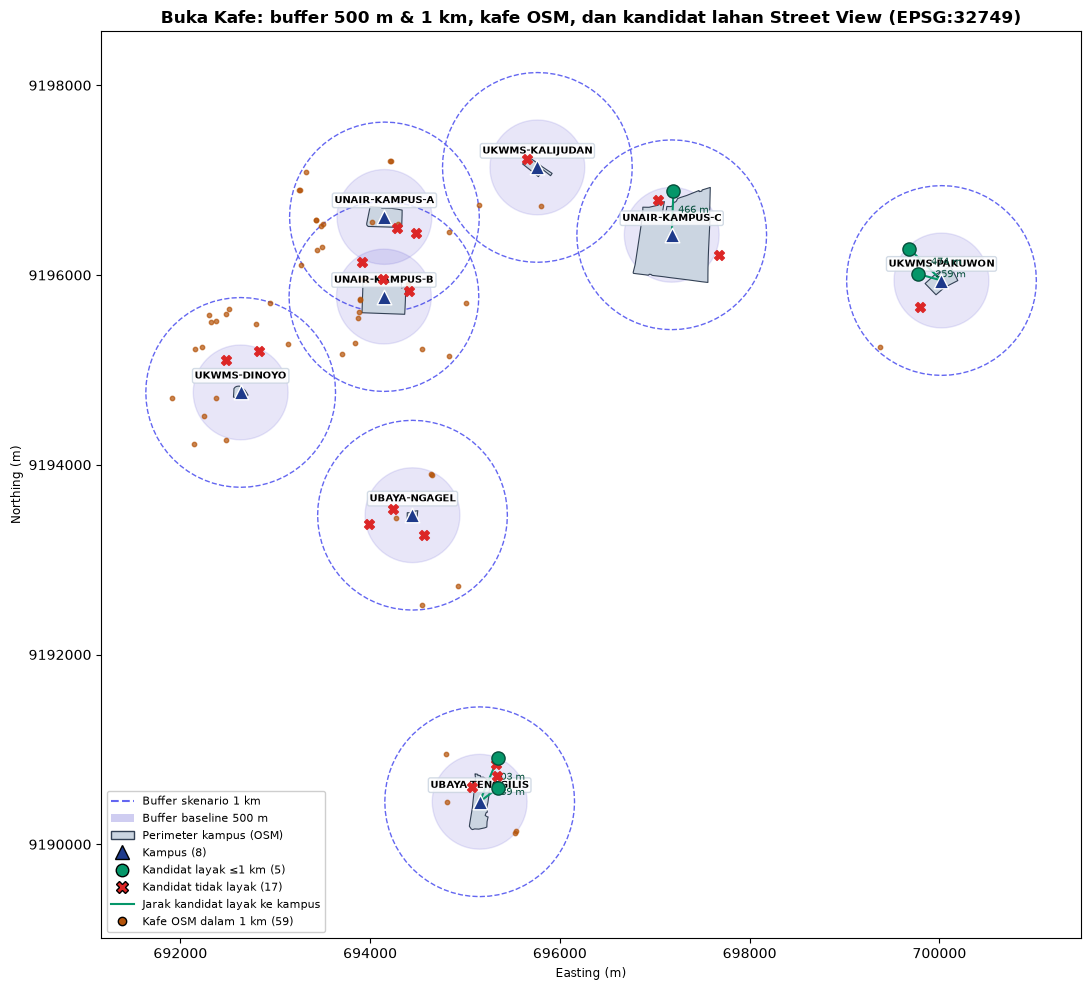

In [18]:
def plot_peta(kampus_titik, kampus_area, zona_500, zona_1000, kafe, kandidat, garis, title, filename=None):
    fig, ax = plt.subplots(figsize=(12, 10))
    zona_1000.plot(ax=ax, facecolor="none", edgecolor="#6366F1", linestyle="--", linewidth=1)
    zona_500.plot(ax=ax, facecolor="#4338CA", alpha=0.12, edgecolor="#4338CA", linewidth=1)
    kampus_area.plot(ax=ax, facecolor="#CBD5E1", edgecolor="#334155", linewidth=0.8)
    kafe.plot(ax=ax, color="#B45309", markersize=10, alpha=0.7, zorder=3)
    garis.plot(ax=ax, color="#059669", linewidth=1.5, zorder=3)
    kandidat.loc[~kandidat["layak_skenario"]].plot(ax=ax, color="#DC2626", marker="X", markersize=50, zorder=4)
    kandidat.loc[kandidat["layak_skenario"]].plot(ax=ax, color="#059669", edgecolor="#064E3B", markersize=90, zorder=5)
    kampus_titik.plot(ax=ax, color="#1E3A8A", marker="^", markersize=110, edgecolor="white", zorder=6)

    for row in kampus_titik.itertuples():
        ax.annotate(row.id, (row.geometry.x, row.geometry.y), xytext=(0, 10), textcoords="offset points",
                    ha="center", fontsize=7.5, fontweight="bold",
                    bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.85, edgecolor="#CBD5E1"))
    for row in garis.itertuples():
        tengah = row.geometry.interpolate(0.5, normalized=True)
        ax.annotate(f"{row.jarak_m:.0f} m", (tengah.x, tengah.y), xytext=(4, 0),
                    textcoords="offset points", fontsize=7, color="#064E3B")

    n_layak = int(kandidat["layak_skenario"].sum())
    legend_items = [
        Line2D([0], [0], color="#6366F1", linestyle="--", label=f"Buffer skenario {lbl_sken}"),
        Patch(facecolor="#4338CA", alpha=0.25, label=f"Buffer baseline {lbl_base}"),
        Patch(facecolor="#CBD5E1", edgecolor="#334155", label="Perimeter kampus (OSM)"),
        Line2D([0], [0], marker="^", color="none", markerfacecolor="#1E3A8A", markersize=10, label=f"Kampus ({len(kampus_titik)})"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor="#059669", markersize=9, label=f"Kandidat layak ≤{lbl_sken} ({n_layak})"),
        Line2D([0], [0], marker="X", color="none", markerfacecolor="#DC2626", markersize=9, label=f"Kandidat tidak layak ({len(kandidat) - n_layak})"),
        Line2D([0], [0], color="#059669", label="Jarak kandidat layak ke kampus"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor="#B45309", markersize=6, label=f"Kafe OSM dalam {lbl_sken} ({len(kafe)})"),
    ]
    ax.legend(handles=legend_items, loc="lower left", fontsize=8, framealpha=0.95)
    ax.set_aspect("equal")
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")
    ax.set_title(title, fontweight="bold")
    ax.ticklabel_format(style="plain", useOffset=False)
    fig.tight_layout()
    if filename:
        fig.savefig(filename, dpi=150)
    plt.show()

plot_peta(
    kampus_m, kampus_poly_m, buffers_500, buffers_1000, kafe_terpotong, lahan_j, garis,
    f"Buka Kafe: buffer {lbl_base} & {lbl_sken}, kafe OSM, dan kandidat lahan Street View (EPSG:32749)",
    filename=ROOT / "notebooks" / "peta_geopandas.png",
)

## 9. Transformasi 2D untuk analisis

Dua transformasi dipakai untuk menjawab pertanyaan analisis. Keduanya ditulis sebagai matriks homogen 3×3:

```
T(tx, ty) = [[1, 0, tx], [0, 1, ty], [0, 0, 1]]      S(sx, sy) = [[sx, 0, 0], [0, sy, 0], [0, 0, 1]]
```

### 9.1 Skenario 1 km = baseline 500 m diskalakan 2×

Skala terhadap titik kampus c: **M = T(c) · S(2, 2) · T(−c)** (geser ke origin → skala → geser balik). Jika hasilnya sama dengan buffer 1 km, berarti skenario hanyalah perbesaran baseline: luasnya naik 2² = 4×, sehingga wilayah yang dianalisis empat kali lebih luas.

In [19]:
def T(tx, ty):
    return np.array([[1, 0, tx], [0, 1, ty], [0, 0, 1]], dtype=float)

def S(sx, sy):
    return np.array([[sx, 0, 0], [0, sy, 0], [0, 0, 1]], dtype=float)

def ke_affine(M):
    # Matriks 3x3 -> parameter [a, b, d, e, xoff, yoff] untuk GeoSeries.affine_transform
    return [M[0, 0], M[0, 1], M[1, 0], M[1, 1], M[0, 2], M[1, 2]]

faktor = skenario_m / baseline_m
hasil_skala = []
for row in kampus_m.itertuples():
    c = row.geometry
    M = T(c.x, c.y) @ S(faktor, faktor) @ T(-c.x, -c.y)
    b500 = buffers_500.set_index("id").loc[row.id, "geometry"]
    b1000 = buffers_1000.set_index("id").loc[row.id, "geometry"]
    hasil = gpd.GeoSeries([b500]).affine_transform(ke_affine(M)).iloc[0]
    selisih = hasil.symmetric_difference(b1000).area
    hasil_skala.append({"kampus": row.id, "luas 500 m (ha)": b500.area / 1e4,
                        "luas hasil skala (ha)": hasil.area / 1e4, "luas 1 km (ha)": b1000.area / 1e4,
                        "rasio luas": hasil.area / b500.area, "selisih vs buffer 1 km (m²)": selisih})
    assert selisih < 1e-3

print("Contoh matriks untuk", kampus_m.iloc[0]["id"])
c0 = kampus_m.geometry.iloc[0]
print(T(c0.x, c0.y) @ S(faktor, faktor) @ T(-c0.x, -c0.y))
print()
print(pd.DataFrame(hasil_skala).round(2).to_string(index=False))
print(f"\nScaling checks passed: buffer {lbl_sken} = buffer {lbl_base} x {faktor:g}, luas x {faktor ** 2:g}.")

Contoh matriks untuk UNAIR-KAMPUS-A
[[       2.          0.    -694150.91]
 [       0.          2.   -9196611.99]
 [       0.          0.          1.  ]]

         kampus  luas 500 m (ha)  luas hasil skala (ha)  luas 1 km (ha)  rasio luas  selisih vs buffer 1 km (m²)
 UNAIR-KAMPUS-A            78.41                 313.65          313.65         4.0                          0.0
 UNAIR-KAMPUS-B            78.41                 313.65          313.65         4.0                          0.0
 UNAIR-KAMPUS-C            78.41                 313.65          313.65         4.0                          0.0
   UKWMS-DINOYO            78.41                 313.65          313.65         4.0                          0.0
UKWMS-KALIJUDAN            78.41                 313.65          313.65         4.0                          0.0
  UKWMS-PAKUWON            78.41                 313.65          313.65         4.0                          0.0
   UBAYA-NGAGEL            78.41                 313.6

### 9.2 Zoom per kampus dengan matriks dunia → piksel

Peta keseluruhan terlalu kecil untuk melihat detail tiap kampus. Matriks zoom memetakan kotak ±1.100 m di sekitar kampus ke panel 300×300 piksel:

**M = T(150, 150) · S(s, −s) · T(−cx, −cy)**, dengan s = 300 / 2.200 piksel per meter. Tanda minus membalik sumbu y karena piksel layar dihitung dari atas ke bawah. Ini rumus yang sama dengan `viewport.js` di web peta.

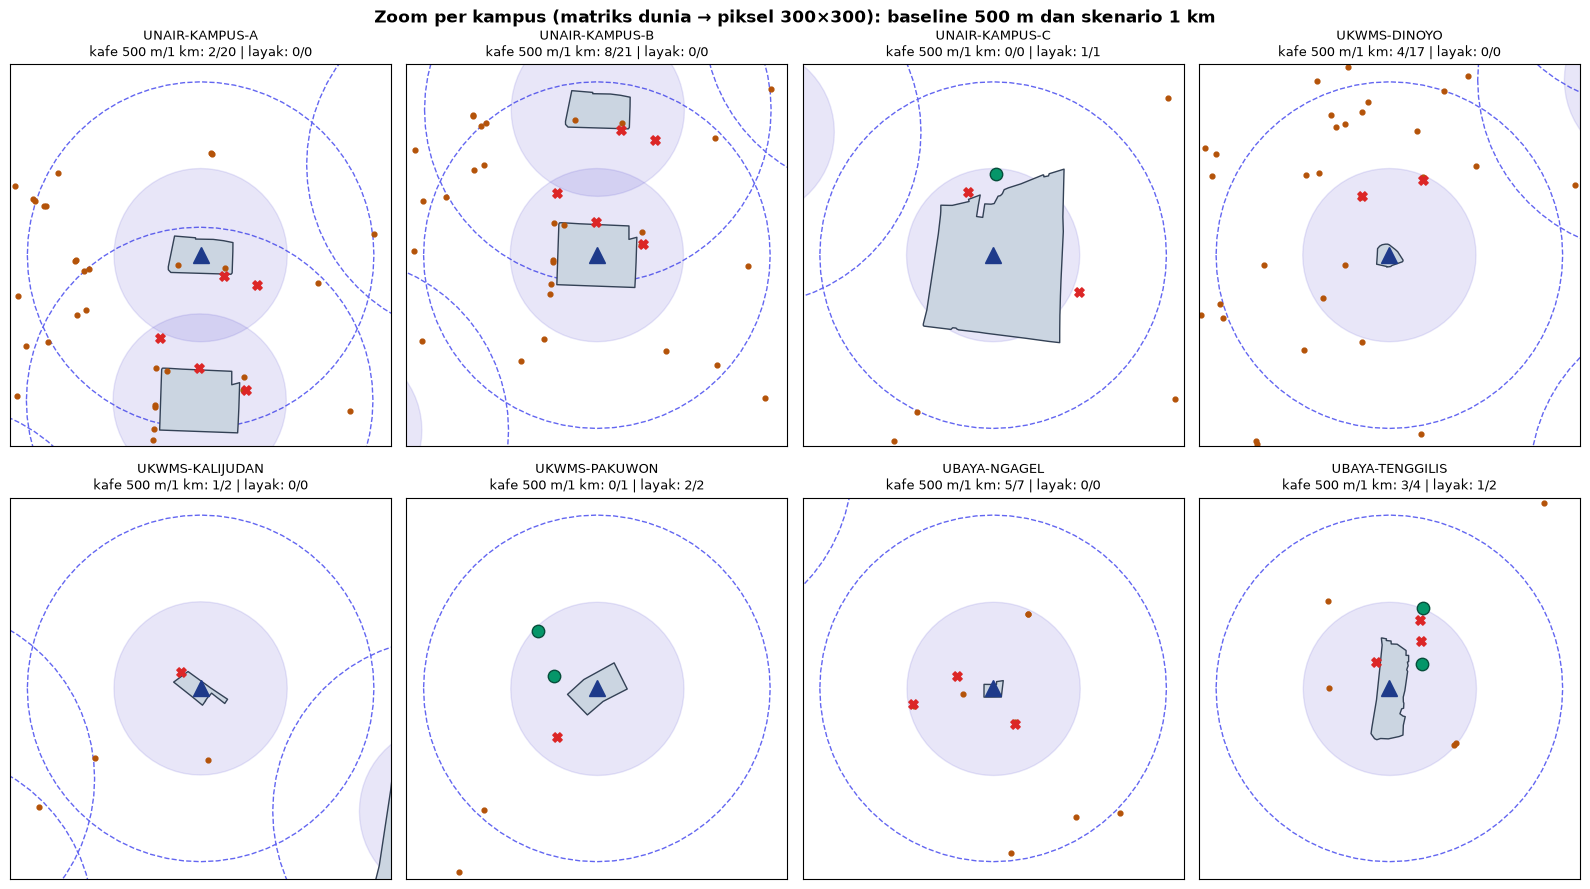

Zoom checks passed: titik kampus selalu jatuh di tengah panel (150, 150).


In [20]:
panel_px, setengah_m = 300, 1100

def matriks_zoom(titik):
    s = panel_px / (2 * setengah_m)
    return T(panel_px / 2, panel_px / 2) @ S(s, -s) @ T(-titik.x, -titik.y)

fig, axes = plt.subplots(2, 4, figsize=(16, 9.2))
for ax, row in zip(axes.flat, per_kampus.itertuples()):
    pusat = titik_kampus[row.id]
    M = ke_affine(matriks_zoom(pusat))
    kotak = pusat.buffer(setengah_m, cap_style="square")

    piksel = lambda gdf: gdf[gdf.intersects(kotak)].geometry.affine_transform(M)
    pusat_px = gpd.GeoSeries([pusat]).affine_transform(M).iloc[0]
    assert abs(pusat_px.x - panel_px / 2) < 1e-6 and abs(pusat_px.y - panel_px / 2) < 1e-6

    piksel(buffers_1000).plot(ax=ax, facecolor="none", edgecolor="#6366F1", linestyle="--")
    piksel(buffers_500).plot(ax=ax, facecolor="#4338CA", alpha=0.12, edgecolor="#4338CA")
    piksel(kampus_poly_m).plot(ax=ax, facecolor="#CBD5E1", edgecolor="#334155")
    piksel(kafe_m).plot(ax=ax, color="#B45309", markersize=12)
    tidak = lahan_j[~lahan_j["layak_skenario"]]
    ya = lahan_j[lahan_j["layak_skenario"]]
    if len(tidak[tidak.intersects(kotak)]):
        piksel(tidak).plot(ax=ax, color="#DC2626", marker="X", markersize=45)
    if len(ya[ya.intersects(kotak)]):
        piksel(ya).plot(ax=ax, color="#059669", edgecolor="#064E3B", markersize=80)
    ax.plot(pusat_px.x, pusat_px.y, marker="^", color="#1E3A8A", markersize=11)

    ax.set_xlim(0, panel_px)
    ax.set_ylim(panel_px, 0)          # piksel: y ke bawah
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(f"{row.id}\nkafe {lbl_base}/{lbl_sken}: {row.kafe_baseline}/{row.kafe_skenario} | layak: {row.layak_baseline}/{row.layak_skenario}",
                 fontsize=9)
fig.suptitle(f"Zoom per kampus (matriks dunia → piksel 300×300): baseline {lbl_base} dan skenario {lbl_sken}", fontweight="bold")
fig.tight_layout(h_pad=2.5)
fig.savefig(ROOT / "notebooks" / "zoom_per_kampus.png", dpi=130)
plt.show()
print("Zoom checks passed: titik kampus selalu jatuh di tengah panel (150, 150).")

## 10. Sensitivitas radius dan animasi

Kenapa 500 m dan 1 km? Grafik di bawah menghitung ulang jumlah kafe OSM pesaing dan lahan layak untuk radius 0–1.500 m (memakai jarak `sjoin_nearest` ke kampus terdekat). Animasi sesudahnya menampilkan hal yang sama di peta: lingkaran buffer semua kampus membesar, dan titik yang masuk berubah warna.

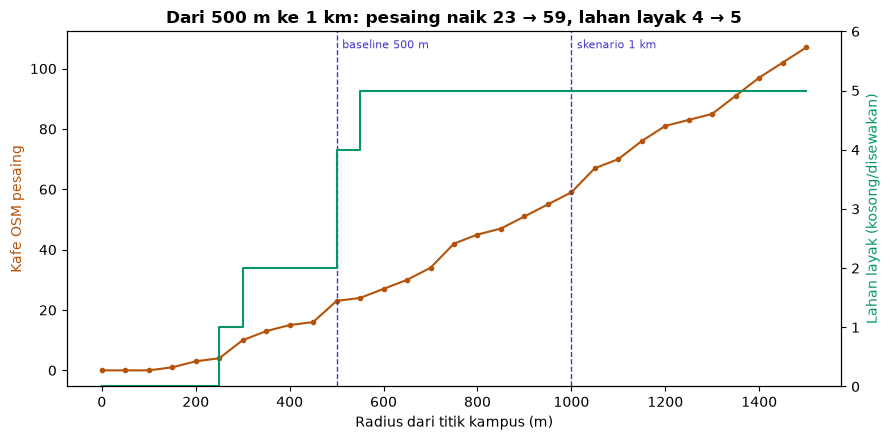

 radius_m  kafe_osm  lahan_layak
      250         4            1
      500        23            4
      750        42            5
     1000        59            5
     1500       107            5


In [21]:
kafe_j = gpd.sjoin_nearest(kafe_m[["osm_id", "geometry"]], kampus_m[["id", "geometry"]], distance_col="jarak_m")
kafe_j = kafe_j[~kafe_j["osm_id"].duplicated()]
radius_uji = np.union1d(np.arange(0, max(1500, skenario_m) + 1, 50), [baseline_m, skenario_m])
sensitivitas = pd.DataFrame({
    "radius_m": radius_uji,
    "kafe_osm": [(kafe_j["jarak_m"] <= r).sum() for r in radius_uji],
    "lahan_layak": [((lahan_j["jarak_kampus_m"] <= r) & lahan_j["bisa_disewa"]).sum() for r in radius_uji],
})
assert sensitivitas.set_index("radius_m").loc[baseline_m, "kafe_osm"] == cakupan_kafe["dalam_baseline"].sum()
assert sensitivitas.set_index("radius_m").loc[skenario_m, "kafe_osm"] == cakupan_kafe["dalam_skenario"].sum()

fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.plot(sensitivitas["radius_m"], sensitivitas["kafe_osm"], color="#B45309", marker="o", markersize=3, label="Kafe OSM pesaing")
ax1.set_xlabel("Radius dari titik kampus (m)")
ax1.set_ylabel("Kafe OSM pesaing", color="#B45309")
ax2 = ax1.twinx()
ax2.step(sensitivitas["radius_m"], sensitivitas["lahan_layak"], where="post", color="#059669", label="Lahan layak")
ax2.set_ylabel("Lahan layak (kosong/disewakan)", color="#059669")
ax2.set_ylim(0, sensitivitas["lahan_layak"].max() + 1)
for r, teks in [(baseline_m, f"baseline {lbl_base}"), (skenario_m, f"skenario {lbl_sken}")]:
    ax1.axvline(r, color="#4338CA", linestyle="--", linewidth=1)
    ax1.annotate(teks, (r, ax1.get_ylim()[1] * 0.95), xytext=(4, 0), textcoords="offset points", fontsize=8, color="#4338CA")
v = sensitivitas.set_index("radius_m")
ax1.set_title(f"Dari {lbl_base} ke {lbl_sken}: pesaing naik {v.loc[baseline_m, 'kafe_osm']} → {v.loc[skenario_m, 'kafe_osm']}, "
              f"lahan layak {v.loc[baseline_m, 'lahan_layak']} → {v.loc[skenario_m, 'lahan_layak']}", fontweight="bold")
fig.tight_layout()
plt.show()
print(sensitivitas[sensitivitas["radius_m"].isin([250, baseline_m, 750, skenario_m, 1500])].to_string(index=False))

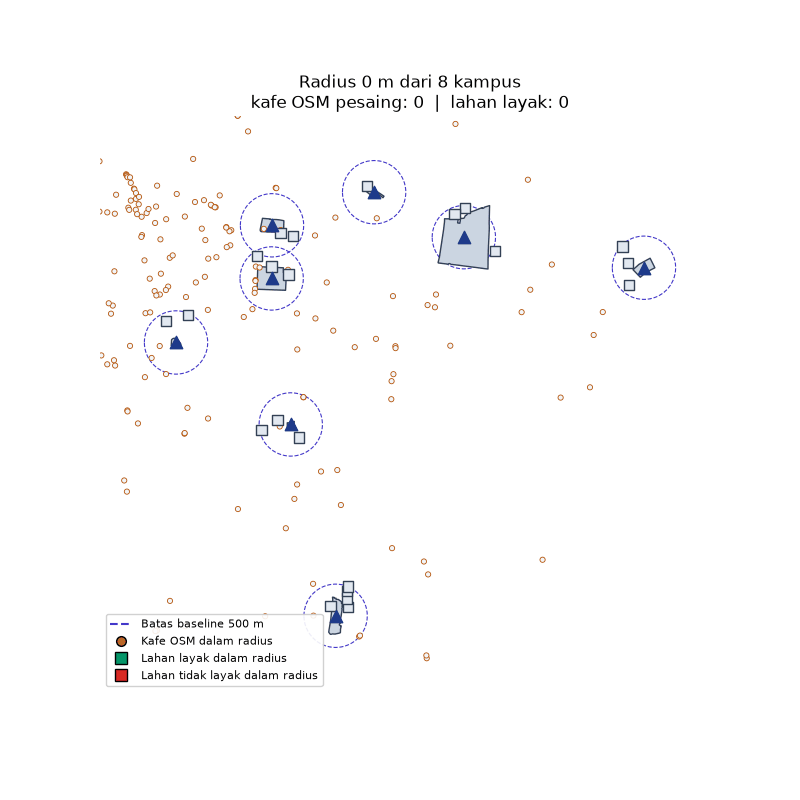

In [22]:
xmin, ymin, xmax, ymax = buffers_1000.total_bounds
frames_radius = list(range(0, skenario_m + 1, 50))
jarak_kafe = kafe_j.set_index("osm_id").loc[kafe_m["osm_id"], "jarak_m"].to_numpy()

fig, ax = plt.subplots(figsize=(8, 8))
ax.set_xlim(xmin - 200, xmax + 200)
ax.set_ylim(ymin - 200, ymax + 200)
ax.set_aspect("equal")
ax.axis("off")
buffers_500.plot(ax=ax, facecolor="none", edgecolor="#4338CA", linestyle="--", linewidth=0.8)
kampus_poly_m.plot(ax=ax, facecolor="#CBD5E1", edgecolor="#334155")
kampus_m.plot(ax=ax, color="#1E3A8A", marker="^", markersize=80, zorder=5)
lingkaran = [plt.Circle((g.x, g.y), 0, facecolor="#6366F1", alpha=0.15, edgecolor="#4338CA") for g in kampus_m.geometry]
for c in lingkaran:
    ax.add_patch(c)
titik_kafe = ax.scatter(kafe_m.geometry.x, kafe_m.geometry.y, s=14, c="#F1F5F9", edgecolors="#B45309", linewidths=0.6, zorder=3)
titik_lahan = ax.scatter(lahan_j.geometry.x, lahan_j.geometry.y, s=55, marker="s", c="#E2E8F0", edgecolors="#334155", zorder=4)
ax.legend(handles=[
    Line2D([0], [0], color="#4338CA", linestyle="--", label=f"Batas baseline {lbl_base}"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#B45309", markersize=7, label="Kafe OSM dalam radius"),
    Line2D([0], [0], marker="s", color="none", markerfacecolor="#059669", markersize=8, label="Lahan layak dalam radius"),
    Line2D([0], [0], marker="s", color="none", markerfacecolor="#DC2626", markersize=8, label="Lahan tidak layak dalam radius"),
], loc="lower left", fontsize=8, framealpha=0.9)
judul = ax.set_title("")
jarak_lahan = lahan_j["jarak_kampus_m"].to_numpy()
bisa = lahan_j["bisa_disewa"].to_numpy()

def gambar_frame(i):
    r = frames_radius[i]
    for c in lingkaran:
        c.set_radius(r)
    titik_kafe.set_facecolor(np.where(jarak_kafe <= r, "#B45309", "#F1F5F9"))
    titik_lahan.set_facecolor(np.where(jarak_lahan <= r, np.where(bisa, "#059669", "#DC2626"), "#E2E8F0"))
    judul.set_text(f"Radius {r} m dari 8 kampus\nkafe OSM pesaing: {(jarak_kafe <= r).sum()}  |  "
                   f"lahan layak: {((jarak_lahan <= r) & bisa).sum()}")
    return [*lingkaran, titik_kafe, titik_lahan, judul]

animasi = FuncAnimation(fig, gambar_frame, frames=len(frames_radius), interval=250)
path_gif = ROOT / "notebooks" / "animasi_buffer.gif"
animasi.save(path_gif, writer=PillowWriter(fps=4))
plt.close(fig)
display(Image(filename=str(path_gif)))

## 11. Ekspor hasil

In [23]:
per_kampus.to_csv(PROC / "geopandas_hasil_per_kampus.csv", index=False)
peringkat.round(2).to_csv(PROC / "geopandas_peringkat_kandidat.csv", index=False)
sensitivitas.to_csv(PROC / "geopandas_sensitivitas_radius.csv", index=False)
print("Tersimpan:")
for f in ["data/processed/geopandas_hasil_per_kampus.csv", "data/processed/geopandas_peringkat_kandidat.csv",
          "data/processed/geopandas_sensitivitas_radius.csv",
          "notebooks/peta_geopandas.png", "notebooks/zoom_per_kampus.png", "notebooks/animasi_buffer.gif"]:
    assert (ROOT / f).exists()
    print(" -", f)

Tersimpan:
 - data/processed/geopandas_hasil_per_kampus.csv
 - data/processed/geopandas_peringkat_kandidat.csv
 - data/processed/geopandas_sensitivitas_radius.csv
 - notebooks/peta_geopandas.png
 - notebooks/zoom_per_kampus.png
 - notebooks/animasi_buffer.gif


## 12. Keterbatasan

1. **Data lahan dari Google Street View.** 22 titik diobservasi lewat panorama Street View pada 1–2 November 2026, bukan survei fisik di lapangan. Tanggal citra 2024–2026, jadi kondisi sekarang bisa berbeda. Semua titik perlu ditinjau tim.
2. **Data sewa dan luas belum ada** untuk titik observasi. Komponen itu tidak ditebak, sehingga cakupan skor di bawah 60%. Dari listing publik, hanya koridor Ubaya Tenggilis yang punya minimal 3 listing terverifikasi (Rp 65–123,5 juta/tahun, median Rp 70 juta); koridor lain belum cukup untuk menyimpulkan harga.
3. **Gerbang kampus dan indikator mahasiswa belum teramati**; tipe jalan hanya diisi bila terlihat jelas di Street View.
4. **Jarak berupa garis lurus** dari titik kampus, bukan jarak tempuh lewat jalan.
5. **Kafe OSM bisa tidak lengkap**: kafe baru atau yang tutup mungkin belum tercatat di OpenStreetMap.
6. **Buffer kampus bisa bertumpuk** (misalnya Unair A dan B), sehingga satu kafe bisa terhitung di dua kampus pada tabel per kampus; total kafe unik dihitung terpisah.